# Análisis y Preparación de Datos — *Metro Interstate Traffic Volume*
## Fase III (Limpieza), Fase IV (Transformación e Ingeniería) y Fase V (Auditoría pre/post)

Continuación del notebook `01_Ingesta_Perfilado_EDA.ipynb`. Aquí se ejecuta el **pipeline de
preparación** con justificación cuantitativa de cada decisión, **evitando fuga de datos
(*data leakage*)**, y se exporta el **dataset limpio** y las **figuras** para el artículo IEEE.

### 0. Entorno, carga y figuras

In [1]:
import os, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

os.makedirs("data", exist_ok=True)
os.makedirs("figs", exist_ok=True)   # figuras para el artículo IEEE

DATA_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"
DATA_PATH = "data/Metro_Interstate_Traffic_Volume.csv.gz"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
# Guardamos una foto del estado 'crudo' para la auditoría pre/post (Fase V)
num_cols = ['temp', 'rain_1h', 'snow_1h', 'clouds_all', 'traffic_volume']
stats_pre = df[num_cols].describe().T.assign(skew=df[num_cols].skew(), kurtosis=df[num_cols].kurtosis())
print("Datos crudos:", df.shape)
df.head(3)

Datos crudos: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767


## Fase III — Limpieza de Datos

### 3.1 Eliminación de duplicados
Primero los **duplicados exactos** (fila idéntica) y luego los **duplicados temporales**
(dos registros para la misma hora, conflicto de origen meteorológico): conservamos el primero.

In [2]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados exactos eliminados: {antes - len(df)}")

antes = len(df)
df = df.drop_duplicates(subset='date_time', keep='first').reset_index(drop=True)
print(f"Duplicados por marca temporal eliminados: {antes - len(df)}")
print("Filas restantes:", len(df))

Duplicados exactos eliminados: 17
Duplicados por marca temporal eliminados: 7612
Filas restantes: 40575


### 3.2 Tratamiento de valores nulos — `holiday`
El nulo en `holiday` **no es aleatorio**: el dataset solo marca el feriado en su hora exacta. Por
tanto, imputar la moda o borrar sería incorrecto. La decisión justificada es **crear la categoría
explícita `"None"`** (ausencia de feriado), que preserva el 100 % de las observaciones y captura
la semántica real de la variable.

In [3]:
print("Nulos en holiday antes:", int(df['holiday'].isna().sum()))
df['holiday'] = df['holiday'].fillna('None')
print("Nulos en holiday después:", int(df['holiday'].isna().sum()))
print(df['holiday'].value_counts().head())

Nulos en holiday antes: 40522
Nulos en holiday después: 0
holiday
None                40522
Columbus Day            5
Veterans Day            5
Thanksgiving Day        5
Christmas Day           5
Name: count, dtype: int64


### 3.3 Tratamiento de outliers — fundamentación cuantitativa

Aplicamos **dos criterios complementarios**:

- **Regla física de dominio** para errores de sensor imposibles:
  `temp = 0 K` (−273 °C) y `rain_1h = 9831 mm/h` (el récord mundial real ronda 305 mm/h).
- **Z-Score** ( $z = \dfrac{x-\mu}{\sigma}$ ) y **IQR** ( $IQR = Q_3 - Q_1$ ) como verificación
  estadística.

> Nota metodológica: en `rain_1h`/`snow_1h` el IQR **no es apropiado** porque son variables
> *cero-infladas* (mediana y cuartiles = 0), lo que marcaría como atípico cualquier lluvia real.
> Por eso en esas variables prima el **criterio físico**; el IQR/Z-Score se usa en `temp`.

In [4]:
# --- temp: 0 K es físicamente imposible -> NaN e imputación por mediana ---
print("Registros con temp = 0 K:", int((df['temp'] == 0).sum()))
df.loc[df['temp'] == 0, 'temp'] = np.nan

# Verificación por Z-Score sobre temp (|z| > 3)
z = np.abs(stats.zscore(df['temp'], nan_policy='omit'))
print("temp con |z| > 3:", int((z > 3).sum()))

mediana_temp = df['temp'].median()
df['temp'] = df['temp'].fillna(mediana_temp)
print(f"temp imputada con la mediana = {mediana_temp:.2f} K")

# --- rain_1h: valor imposible (>500 mm/h) -> corrección ---
print("\nrain_1h > 500 mm/h (imposible):", int((df['rain_1h'] > 500).sum()), "| máx =", df['rain_1h'].max())
df.loc[df['rain_1h'] > 500, 'rain_1h'] = df['rain_1h'].median()
print("Nuevo máximo de rain_1h:", df['rain_1h'].max())

# IQR de temp (referencia estadística)
Q1, Q3 = df['temp'].quantile([0.25, 0.75])
IQR = Q3 - Q1
print(f"\ntemp -> Q1={Q1:.1f}  Q3={Q3:.1f}  IQR={IQR:.1f}  límites=[{Q1-1.5*IQR:.1f}, {Q3+1.5*IQR:.1f}]")

Registros con temp = 0 K: 10
temp con |z| > 3: 0
temp imputada con la mediana = 282.87 K

rain_1h > 500 mm/h (imposible): 1 | máx = 9831.3
Nuevo máximo de rain_1h: 55.63

temp -> Q1=271.9  Q3=292.3  IQR=20.4  límites=[241.2, 322.9]


### 3.4 Estandarización de texto y fechas
- `weather_description`: normalizamos a minúsculas y sin espacios sobrantes (inconsistencias
  tipográficas).
- `date_time`: convertimos a tipo `datetime` para habilitar la ingeniería temporal.

In [5]:
df['weather_description'] = df['weather_description'].str.strip().str.lower()
df['weather_main'] = df['weather_main'].str.strip()

df['date_time'] = pd.to_datetime(df['date_time'], errors='coerce')
print("Fechas no convertidas (NaT):", int(df['date_time'].isna().sum()))
print("Rango temporal:", df['date_time'].min(), "->", df['date_time'].max())
print("Tipos tras la limpieza:\n", df.dtypes)

Fechas no convertidas (NaT): 0
Rango temporal: 2012-10-02 09:00:00 -> 2018-09-30 23:00:00
Tipos tras la limpieza:
 holiday                           str
temp                          float64
rain_1h                       float64
snow_1h                       float64
clouds_all                      int64
weather_main                      str
weather_description               str
date_time              datetime64[us]
traffic_volume                  int64
dtype: object


## Fase IV — Transformación, Normalización e Ingeniería de Características

### 4.1 Ingeniería de características temporales y derivadas
A partir de `date_time` y `temp` creamos variables con valor analítico:
`hora`, `dia_semana`, `mes`, `es_finde`, `hora_pico`, `estacion` y `temp_c` (°C).

In [6]:
df['hora']       = df['date_time'].dt.hour
df['dia_semana']  = df['date_time'].dt.dayofweek          # 0 = lunes
df['mes']         = df['date_time'].dt.month
df['es_finde']    = (df['dia_semana'] >= 5).astype(int)
df['hora_pico']   = df['hora'].isin([7, 8, 16, 17]).astype(int)
df['temp_c']      = (df['temp'] - 273.15).round(2)         # Kelvin -> Celsius
df['es_feriado']  = (df['holiday'] != 'None').astype(int)

estaciones = {12:'Invierno',1:'Invierno',2:'Invierno', 3:'Primavera',4:'Primavera',5:'Primavera',
              6:'Verano',7:'Verano',8:'Verano', 9:'Otoño',10:'Otoño',11:'Otoño'}
df['estacion'] = df['mes'].map(estaciones)

print("Nuevas variables creadas:")
print(df[['hora','dia_semana','mes','es_finde','hora_pico','temp_c','es_feriado','estacion']].head())

Nuevas variables creadas:
   hora  dia_semana  mes  es_finde  hora_pico  temp_c  es_feriado estacion
0     9           1   10         0          0   15.13           0    Otoño
1    10           1   10         0          0   16.21           0    Otoño
2    11           1   10         0          0   16.43           0    Otoño
3    12           1   10         0          0   16.98           0    Otoño
4    13           1   10         0          0   17.99           0    Otoño


### 4.2 Separación train/test ANTES de escalar/codificar (evita *data leakage*)
La regla de oro: los parámetros de escalado y codificación se **aprenden solo con el conjunto de
entrenamiento** y luego se aplican al de prueba, para no filtrar información del test.

In [7]:
features_num = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'hora', 'mes']
features_cat = ['weather_main']            # se codifica con One-Hot
target = 'traffic_volume'

X = df[features_num + features_cat + ['es_finde','hora_pico','es_feriado']].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (32460, 10) | Test: (8115, 10)


### 4.3 Codificación de variables categóricas (One-Hot, evitando la trampa de las *dummies*)
`weather_main` se convierte con **One-Hot Encoding** usando `drop_first=True` para eliminar una
categoría de referencia y **evitar la multicolinealidad perfecta** (trampa de las variables
ficticias).

In [8]:
X_train = pd.get_dummies(X_train, columns=['weather_main'], drop_first=True)
X_test  = pd.get_dummies(X_test,  columns=['weather_main'], drop_first=True)
# Alinear columnas (garantiza que test tenga las mismas dummies que train)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print("Nº de columnas tras One-Hot:", X_train.shape[1])
print([c for c in X_train.columns if c.startswith('weather_main_')])

Nº de columnas tras One-Hot: 19
['weather_main_Clouds', 'weather_main_Drizzle', 'weather_main_Fog', 'weather_main_Haze', 'weather_main_Mist', 'weather_main_Rain', 'weather_main_Smoke', 'weather_main_Snow', 'weather_main_Squall', 'weather_main_Thunderstorm']


### 4.4 Escalado numérico — elección justificada
- **`RobustScaler`** ( $x' = \dfrac{x - \text{mediana}}{IQR}$ ) para `rain_1h` y `snow_1h`: son
  variables con **colas pesadas y outliers**, y este escalador usa mediana e IQR (resistentes).
- **`StandardScaler`** ( $z = \dfrac{x-\mu}{\sigma}$ ) para `temp_c`, `clouds_all`, `hora`, `mes`:
  distribuciones más simétricas y acotadas.

Ambos se **ajustan con `X_train`** y se aplican a `X_train` y `X_test`.

In [9]:
col_robust   = ['rain_1h', 'snow_1h']
col_standard = ['temp_c', 'clouds_all', 'hora', 'mes']

rs, ss = RobustScaler(), StandardScaler()
X_train_esc, X_test_esc = X_train.copy(), X_test.copy()

X_train_esc[col_robust]   = rs.fit_transform(X_train[col_robust])
X_test_esc[col_robust]    = rs.transform(X_test[col_robust])
X_train_esc[col_standard] = ss.fit_transform(X_train[col_standard])
X_test_esc[col_standard]  = ss.transform(X_test[col_standard])

print("Escalado aplicado sin fuga de datos (fit solo en train).")
X_train_esc[col_robust + col_standard].describe().T[['mean','std','min','max']].round(3)

Escalado aplicado sin fuga de datos (fit solo en train).


,mean,std,min,max
rain_1h,0.073,0.774,0.000,55.630
snow_1h,0.000,0.006,0.000,0.510
temp_c,-0.000,1.000,-2.893,2.187
clouds_all,0.000,1.000,-1.140,1.445
hora,0.000,1.000,-1.655,1.652
mes,-0.000,1.000,-1.627,1.633


## Fase V — Auditoría y Comparación Pre/Post Procesamiento

### 5.1 Comparación de métricas estadísticas (crudo vs. limpio)
Comparamos media, desviación, asimetría y curtosis antes y después de la limpieza de outliers.

In [10]:
stats_post = df[num_cols].describe().T.assign(skew=df[num_cols].skew(), kurtosis=df[num_cols].kurtosis())
comp = pd.concat(
    [stats_pre[['mean','std','skew','kurtosis']].add_suffix('_PRE'),
     stats_post[['mean','std','skew','kurtosis']].add_suffix('_POST')], axis=1)
comp = comp[['mean_PRE','mean_POST','std_PRE','std_POST','skew_PRE','skew_POST','kurtosis_PRE','kurtosis_POST']]
comp.round(3)

,mean_PRE,mean_POST,std_PRE,std_POST,skew_PRE,skew_POST,kurtosis_PRE,kurtosis_POST
temp,281.206,281.386,13.338,13.092,-2.247,-0.383,39.915,-0.692
rain_1h,0.334,0.076,44.789,0.770,219.389,28.644,48155.627,1321.760
snow_1h,0.000,0.000,0.008,0.006,48.367,65.907,2620.466,4968.367
clouds_all,49.362,44.199,39.016,38.683,-0.197,0.030,-1.742,-1.763
traffic_volume,3259.818,3290.650,1986.861,1984.773,-0.089,-0.107,-1.309,-1.297


El cambio más marcado está en `temp` (la media sube al eliminar los `0 K`) y en `rain_1h`, cuya
**asimetría y curtosis se desploman** al corregir el outlier de 9831 mm — el ruido extremo deja de
dominar la distribución.

### 5.2 Distribuciones antes vs. después (evidencia visual)

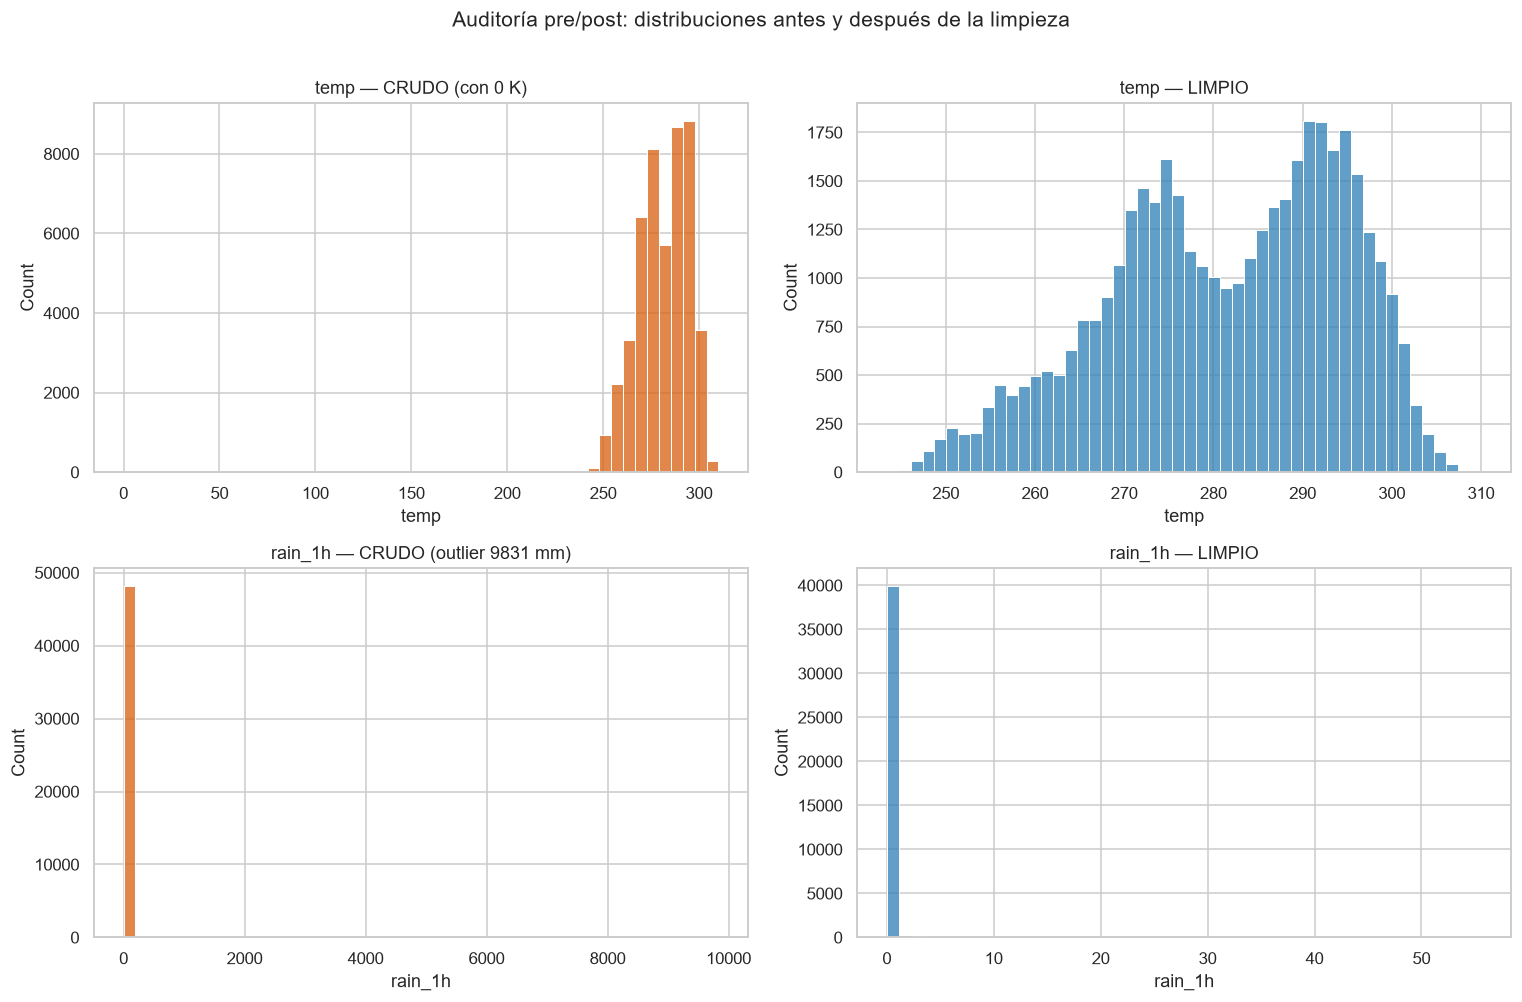

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(df_raw['temp'], bins=50, ax=axes[0,0], color="#d95f0e")
axes[0,0].set_title("temp — CRUDO (con 0 K)")
sns.histplot(df['temp'], bins=50, ax=axes[0,1], color="#2c7fb8")
axes[0,1].set_title("temp — LIMPIO")
sns.histplot(df_raw['rain_1h'], bins=50, ax=axes[1,0], color="#d95f0e")
axes[1,0].set_title("rain_1h — CRUDO (outlier 9831 mm)")
sns.histplot(df['rain_1h'], bins=50, ax=axes[1,1], color="#2c7fb8")
axes[1,1].set_title("rain_1h — LIMPIO")
fig.suptitle("Auditoría pre/post: distribuciones antes y después de la limpieza", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("figs/fig_pre_post_distribuciones.png", bbox_inches="tight", dpi=150)
plt.show()

### 5.3 Boxplots pre/post y matriz de correlación final

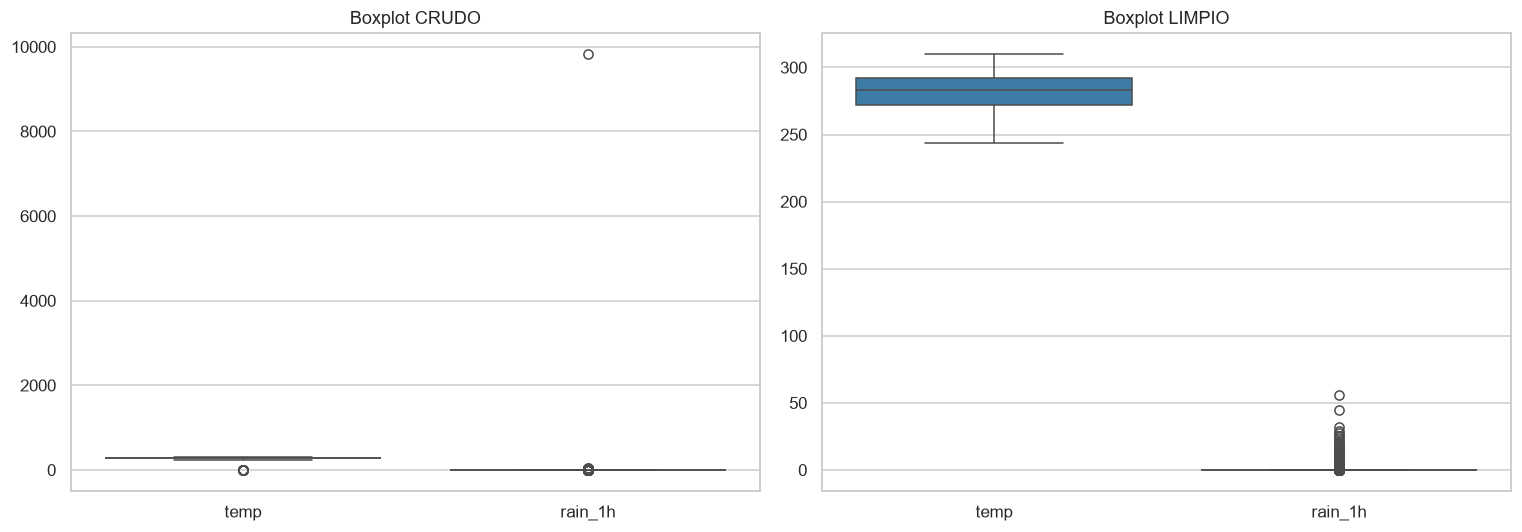

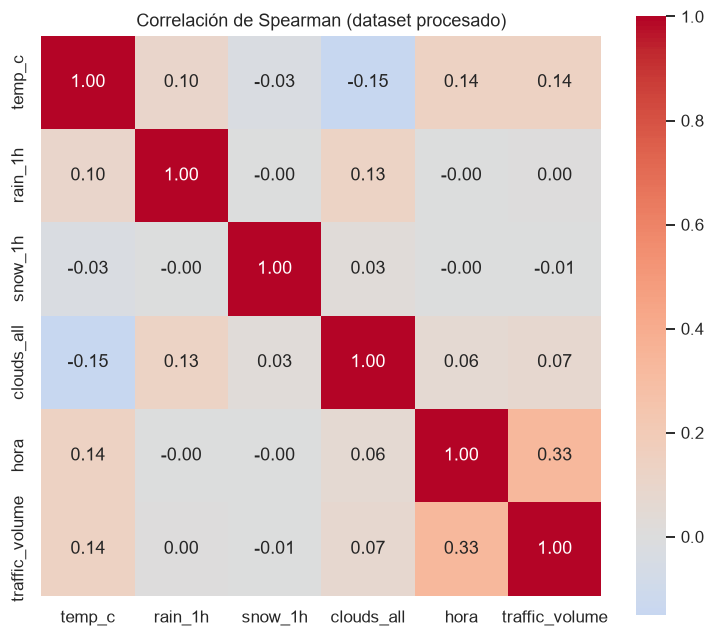

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_raw[['temp','rain_1h']], ax=axes[0], color="#d95f0e")
axes[0].set_title("Boxplot CRUDO")
sns.boxplot(data=df[['temp','rain_1h']], ax=axes[1], color="#2c7fb8")
axes[1].set_title("Boxplot LIMPIO")
plt.tight_layout()
plt.savefig("figs/fig_pre_post_boxplots.png", bbox_inches="tight", dpi=150)
plt.show()

plt.figure(figsize=(7, 6))
corr_fin = df[['temp_c','rain_1h','snow_1h','clouds_all','hora','traffic_volume']].corr(method='spearman')
sns.heatmap(corr_fin, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlación de Spearman (dataset procesado)")
plt.tight_layout()
plt.savefig("figs/fig_correlacion_final.png", bbox_inches="tight", dpi=150)
plt.show()

### 5.4 Exportación del dataset limpio y transformado
Guardamos el dataset **limpio + con variables derivadas** (legible) como entregable, y confirmamos
que las matrices `X_train_esc` / `X_test_esc` quedan **listas para modelado** (numéricas, escaladas
y codificadas, sin nulos).

In [13]:
cols_export = ['date_time','traffic_volume','temp_c','rain_1h','snow_1h','clouds_all',
               'weather_main','weather_description','holiday','es_feriado',
               'hora','dia_semana','mes','estacion','es_finde','hora_pico']
df_clean = df[cols_export].copy()
df_clean.to_csv("data/Metro_Interstate_Traffic_Volume_clean.csv", index=False)

print("Dataset limpio exportado -> data/Metro_Interstate_Traffic_Volume_clean.csv")
print("Dimensiones dataset limpio:", df_clean.shape)
print("Nulos totales en el dataset limpio:", int(df_clean.isna().sum().sum()))
print("Matriz ML lista -> X_train:", X_train_esc.shape, "| X_test:", X_test_esc.shape)
print("Nulos en X_train_esc:", int(X_train_esc.isna().sum().sum()))
df_clean.head()

Dataset limpio exportado -> data/Metro_Interstate_Traffic_Volume_clean.csv
Dimensiones dataset limpio: (40575, 16)
Nulos totales en el dataset limpio: 0
Matriz ML lista -> X_train: (32460, 19) | X_test: (8115, 19)
Nulos en X_train_esc: 0


,date_time,traffic_volume,temp_c,rain_1h,snow_1h,clouds_all,weather_main,weather_description,holiday,es_feriado,hora,dia_semana,mes,estacion,es_finde,hora_pico
0,2012-10-02 09:00:00,5545,15.13,0.0,0.0,40,Clouds,scattered clouds,None,0,9,1,10,Otoño,0,0
1,2012-10-02 10:00:00,4516,16.21,0.0,0.0,75,Clouds,broken clouds,None,0,10,1,10,Otoño,0,0
2,2012-10-02 11:00:00,4767,16.43,0.0,0.0,90,Clouds,overcast clouds,None,0,11,1,10,Otoño,0,0
3,2012-10-02 12:00:00,5026,16.98,0.0,0.0,90,Clouds,overcast clouds,None,0,12,1,10,Otoño,0,0
4,2012-10-02 13:00:00,4918,17.99,0.0,0.0,75,Clouds,broken clouds,None,0,13,1,10,Otoño,0,0


### 5.5 Conclusiones del pipeline
- Se eliminaron **duplicados** (exactos y temporales) y se resolvió el nulo estructural de
  `holiday` con una **categoría explícita**, preservando el 100 % de observaciones válidas.
- El tratamiento de outliers combinó **criterio físico** (errores de sensor) y **verificación
  estadística** (Z-Score/IQR), reduciendo drásticamente la asimetría y curtosis de `rain_1h`.
- La transformación aplicó **escalado mixto** (Robust + Standard) según la forma de cada variable y
  **One-Hot con `drop_first`** para evitar multicolinealidad, todo **sin fuga de datos**.
- Se crearon **7 variables derivadas** con valor analítico (temporales, estacionales y `temp_c`).
- El dataset resultante queda **sin nulos, sin outliers imposibles y con escalas homogéneas**,
  listo para el entrenamiento de modelos de ML/BI.

**Entregables generados por este notebook:** `data/Metro_Interstate_Traffic_Volume_clean.csv` y las
figuras en `figs/` para el artículo IEEE.